# 11 · A3 stage 2: AETHER's recipe on US farm country, with NASA POWER and OpenStreetMap (U1, C1)

Settings fixed in `PLAN.md` (A3, A3.1, A3.2) and `configs/aether_us.yaml` before this notebook ran.

- **Location** = one 30 m pixel: AlphaEarth (64) plus the POWER summary vector of its cell (907), standardised.
- **Model** = AETHER's MLP projector (3 layers, 512 wide) into a frozen text space; **loss** = their soft
  contrastive loss (our port, checked in notebook 09), sigma 0.1, learnable temperature.
- **Captions** = A2's generator (land, distance, patch, climate facts) plus OpenStreetMap tags (notebook 10).
- **Text encoders**: their frozen CLIP ViT-L-14 text tower, and (C1) Qwen3-Embedding-0.6B.
- **U1 (a)**: their concept-retrieval index in the held-out states (Minnesota, Georgia), mean over fact groups.
  **U1 (b)**: persona questions, AP − chance. **C1**: the U1 (a) difference between the two text encoders.

In [1]:
import json
import time

import numpy as np
import pandas as pd

from askmap.catalogue import area_classes
from askmap.config import PROJECT_ROOT, data_root, load_config
from askmap.layers import SOLAR_LATER, official_leaf_map
from askmap.plan import AreaContext, execute
from askmap.power import add_derived, fetch_daily, pixel_cells
from askmap.tiles import area_tiles, pixel_lonlat
from askmap.universe import Universe, box_of

cfg = load_config(PROJECT_ROOT / "configs" / "feasibility.yaml")
Q = load_config(PROJECT_ROOT / "configs" / "queries.yaml")["queries"]
RW = load_config(PROJECT_ROOT / "configs" / "reworded.yaml")["reworded"]
ROOT = data_root()
RES = PROJECT_ROOT / "outputs" / "results"
FIG = PROJECT_ROOT / "outputs" / "figures"
CL, P, SC = cfg["classes"], cfg["power"], cfg["scoring"]
LEAVES, GROUPS = CL["leaves"], CL["groups"]
CATALOGUE = area_classes(cfg)
T_START = time.time()
cells = pd.read_parquet(ROOT / "power" / "universe_cells.parquet")
daily = {
    box: add_derived(fetch_daily(P, b, ROOT / "power" / f"universe_{box}_daily.nc"), P["low_wind_sun_pct"])
    for box, b in P["boxes"].items()
}
uni = Universe(cells=cells, daily=daily)
SEEN = ["north_dakota", "north_carolina"]
HELD = cfg["heldout_pools"]  # seen area -> held-out state
POOL_Q = {
    "north_dakota": "north_dakota",
    "north_carolina": "north_carolina",
    "minnesota": "north_dakota",
    "georgia": "north_carolina",
}  # pool -> area whose questions it answers
T = {}
for area in POOL_Q:
    for name, (tile, role) in area_tiles(cfg["areas"][area], cfg["grid"]).items():
        z = np.load(ROOT / "tiles" / f"{area}_{name}.npz")
        solar = z["solar"] if "solar" in z.files else None
        nwi = z["nwi"] if "nwi" in z.files else None
        valid = np.isfinite(z["ae"]).all(axis=0)
        if solar is not None:
            valid &= solar != SOLAR_LATER
        lon, lat = pixel_lonlat(tile)
        box = box_of(float(lon.mean()), float(lat.mean()), P["boxes"])
        iy, ix = pixel_cells(daily[box].lat.values, daily[box].lon.values, lat, lon)
        T[name] = {
            "area": area,
            "role": role,
            "valid": valid,
            "box": box,
            "iy": iy,
            "ix": ix,
            "cell": uni.index(box, iy, ix),
            "official": official_leaf_map(z["cdl"], LEAVES, CL, nwi=nwi, solar=solar),
        }
        if role == "test":
            T[name]["ae_map"] = np.load(ROOT / "maps" / f"ae_{name}.npz")["leaf"]
            T[name]["planted_map"] = np.load(ROOT / "maps" / f"planted_{name}.npz")["leaf"]
CTX, TILES = {}, {}
for area in POOL_Q:
    names = [n for n, t in T.items() if t["area"] == area]
    ds = daily[T[names[0]]["box"]]
    ac = np.zeros((ds.sizes["lat"], ds.sizes["lon"]), bool)
    for n in names:
        ac[T[n]["iy"], T[n]["ix"]] = True
    CTX[area] = AreaContext(
        leaves=LEAVES,
        groups=GROUPS,
        res_m=cfg["grid"]["res_m"],
        power=ds,
        area_cells=ac,
        pixel_cell={n: (T[n]["iy"], T[n]["ix"]) for n in names},
    )
    TILES[area] = {
        "train": [n for n in names if T[n]["role"] == "train"],
        "test": [n for n in names if T[n]["role"] == "test"],
    }


def answer(plan, pool, maps="official"):
    """Answer of a plan in a pool's test tiles, as one vector over their valid pixels (fixed tile order)."""
    tiles = TILES[pool]["test"]
    key = "official" if maps == "official" else f"{maps}_map"
    got = execute(plan, {n: T[n][key] for n in tiles}, CTX[pool])
    return np.concatenate([got[n][T[n]["valid"]] for n in tiles])


def question_text(q, wording, pool):
    text = q["question"] if wording != "reworded" else RW[q["id"]]
    if pool in ("minnesota", "georgia"):
        text = text.replace("North Dakota", "Minnesota").replace("North Carolina", "Georgia")
    return text


def n_extra(plan):
    return len(plan["near"]) + len(plan["climate"]) + int(plan["land"]["min_patch_ha"] is not None)


print(f"{len(T)} tiles loaded; pools {dict((a, TILES[a]['test']) for a in POOL_Q)}")

18 tiles loaded; pools {'north_dakota': ['Kidder', 'Foster', 'Eddy'], 'north_carolina': ['NC4', 'NC5', 'NC6'], 'minnesota': ['MN1', 'MN2', 'MN3'], 'georgia': ['GA1', 'GA2', 'GA3']}


In [2]:
import os

import matplotlib.pyplot as plt
import torch
from sklearn.metrics import average_precision_score

from askmap.aether_us import (
    Bank,
    TileScores,
    captions_for,
    climate_only_spec,
    concept_indices,
    group_mean,
    multiset_index,
    project,
    similarities,
    text_vectors,
    train,
)
from askmap.captions import Location, Vocab, fact_text, near_text
from askmap.layers import class_mask
from askmap.local_facts import distances, leaf_patch_ha, patch_area_ha, sample_pixels
from askmap.space import Items, specs_from

AU = load_config(PROJECT_ROOT / "configs" / "aether_us.yaml")
CAP = load_config(PROJECT_ROOT / "configs" / "captions.yaml")
SM, MCFG, CC, ACAP = cfg["sampling"], AU["model"], AU["concepts"], AU["captions"]
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
f = np.load(ROOT / "climate" / "facts.npz")
FACT_IDS, TABLE = [str(x) for x in f["ids"]], f["table"]
FAMILY = np.array(["long" if i.split("|")[0] == "sun" else i.split("|")[0] for i in FACT_IDS])
SUMMARY = np.load(ROOT / "climate" / "enc_summary.npy")
vocab = Vocab(CAP, LEAVES, GROUPS, FACT_IDS)
NEAR = vocab.near_classes
OTHER = LEAVES.index("other")
RES_M = cfg["grid"]["res_m"]
NPX = round(cfg["grid"]["tile_size_m"] / RES_M)
OV = AU["osm"]["vocab"]
USED = pd.read_csv(RES / "10_osm_used.csv").entry.tolist()
WORDS = [OV[k]["words"] for k in USED]
OUT = ROOT / "aether_us"
OUT.mkdir(exist_ok=True)
HF_CACHE = os.environ["HF_HOME"]
print(f"device {device}; {len(USED)} OpenStreetMap entries used; {len(FACT_IDS)} climate facts")


def osm_layers(area, name):
    z = np.load(ROOT / "osm" / f"{area}_{name}.npz")
    return np.stack([np.unpackbits(z[k])[: NPX * NPX].reshape(NPX, NPX) for k in USED]).astype(bool)


def local(leaf):
    return {
        "dist": distances(leaf, NEAR, LEAVES, GROUPS, RES_M),
        "patch_leaf": leaf_patch_ha(leaf, len(LEAVES), RES_M),
        "patch_crop": patch_area_ha(class_mask(leaf, "cropland", LEAVES, GROUPS), RES_M),
    }

device mps; 23 OpenStreetMap entries used; 4006 climate facts


## Training locations (A2's sample: 5,000 pixels per training tile) with OpenStreetMap tags

In [3]:
parts = []
for k, (area, acfg) in enumerate(cfg["areas"].items()):
    for j, (name, (tile, role)) in enumerate(area_tiles(acfg, cfg["grid"]).items()):
        if role != "train":
            continue
        z = np.load(ROOT / "tiles" / f"{area}_{name}.npz")
        solar = z["solar"] if "solar" in z.files else None
        nwi = z["nwi"] if "nwi" in z.files else None
        leaf = official_leaf_map(z["cdl"], LEAVES, CL, nwi=nwi, solar=solar)
        valid = np.isfinite(z["ae"]).all(axis=0) & (leaf != OTHER)
        if solar is not None:
            valid &= solar != SOLAR_LATER
        lon, lat = pixel_lonlat(tile)
        box = box_of(float(lon.mean()), float(lat.mean()), P["boxes"])
        iy, ix = pixel_cells(daily[box].lat.values, daily[box].lon.values, lat, lon)
        cell = uni.index(box, iy, ix)
        lf = local(leaf)
        flat = sample_pixels(leaf, valid, SM["train_pixels_per_tile"], len(LEAVES), SM["seed"] + 100 * k + j)
        parts.append(
            {
                "ae": z["ae"].reshape(64, -1)[:, flat].T.astype(np.float32),
                "leaf": leaf.ravel()[flat],
                "dist": lf["dist"].reshape(-1, len(NEAR))[flat],
                "patch_leaf": lf["patch_leaf"].ravel()[flat],
                "patch_crop": lf["patch_crop"].ravel()[flat],
                "cell": cell.ravel()[flat],
                "osm": osm_layers(area, name).reshape(len(USED), -1)[:, flat].T,
                "area": np.full(len(flat), area),
            }
        )
LOC = {key: np.concatenate([p[key] for p in parts]) for key in parts[0]}
assert not cells.heldout.to_numpy()[LOC["cell"]].any()
N = len(LOC["leaf"])
XRAW = np.c_[LOC["ae"], SUMMARY[LOC["cell"]]]
MU, SD = XRAW.mean(0), XRAW.std(0)
SD[SD == 0] = 1.0


def standardise(ae, cell):
    return ((np.c_[ae, SUMMARY[cell]] - MU) / SD).astype(np.float32)


X = standardise(LOC["ae"], LOC["cell"])
print(
    f"{N:,} training locations; {X.shape[1]} inputs; share with any OpenStreetMap tag "
    f"{LOC['osm'].any(axis=1).mean():.2f}"
)

85,000 training locations; 971 inputs; share with any OpenStreetMap tag 0.17


## Captions (A2's generator + OpenStreetMap) and climate-only captions attached to a location of their cell

In [4]:
rng = np.random.default_rng(ACAP["seed"])
cache = {}


def true_facts(c):
    if c not in cache:
        on = np.flatnonzero(TABLE[c])
        cache[c] = {fam: on[FAMILY[on] == fam] for fam in ("hist", "heat", "rain", "gdd", "long")}
    return cache[c]


locs = [
    Location(
        int(LOC["leaf"][j]),
        LOC["dist"][j],
        float(LOC["patch_leaf"][j]),
        float(LOC["patch_crop"][j]),
        true_facts(int(LOC["cell"][j])),
        str(LOC["area"][j]),
    )
    for j in range(N)
]
rows = captions_for(locs, LOC["osm"], vocab, WORDS, AU["osm"]["join"], ACAP, rng)
comp = CAP["composition"]
fams = ["hist", "heat", "rain", "gdd", "long"]
fam_p = np.array([comp["climate_year"] / 4] * 4 + [comp["climate_long"]])
members = pd.Series(np.arange(N)).groupby(LOC["cell"]).apply(np.array)
for c, mem in members.items():
    tf = true_facts(int(c))
    for _ in range(ACAP["climate_only_per_cell"]):
        order = [fm for fm in rng.choice(fams, size=5, replace=False, p=fam_p / fam_p.sum()) if len(tf[fm])]
        fid = int(rng.choice(tf[order[0]]))
        rows.append(
            {
                "item": int(rng.choice(mem)),
                "osm": -1,
                "text": str(rng.choice(CAP["prefixes"]))
                + fact_text(FACT_IDS[fid], CAP, int(rng.integers(3))),
                "spec": climate_only_spec(len(LEAVES), len(NEAR), fid),
            }
        )
caps = pd.DataFrame(rows)
print(f"{len(caps):,} captions ({(caps.osm >= 0).mean():.2%} with an OpenStreetMap fact)")
caps.text.sample(12, random_state=0).tolist()

510,930 captions (5.91% with an OpenStreetMap fact)


['hayfields in the North Dakota study area',
 'grassland and pasture within 2 km of forest',
 'other annual crops no more than 2 km away from built-up land',
 'Show grassland and pasture',
 'Show grassland and pasture and canola fields no more than 1 km away from any open water in the North Carolina study area',
 'Show minor annual crops not within 30 m of trees',
 'Show farmland under annual crops',
 'Find woodland in patches of at least 10 ha in Virginia',
 'woodland',
 'Find hay land where July 2025 had at least 15 days with a daily maximum above 30 C, mapped in OpenStreetMap as farmland',
 'Show hay land with 200 mm or more of rain in summer (June-August) 2018, where the map shows a golf club',
 'Find farmland under annual crops in patches of at least 20 ha']

## Concepts for their index (one caption each, wording 0)

In [5]:
def fact_year(fid):
    p = fid.split("|")
    return {
        "hist": p[3] if len(p) > 3 else None,
        "heat": p[3] if len(p) > 3 else None,
        "rain": p[2] if len(p) > 2 else None,
        "gdd": p[1] if len(p) > 1 else None,
    }.get(p[0])


CONCEPTS = [
    {"group": "land", "name": n, "text": CAP["land"][n][0], "kind": "land", "arg": n}
    for n in [x for x in LEAVES if x != "other"] + list(GROUPS)
]
CONCEPTS += [
    {"group": "osm", "name": k, "text": OV[k]["words"][0], "kind": "osm", "arg": i}
    for i, k in enumerate(USED)
]
CONCEPTS += [
    {
        "group": "distance",
        "name": f"near_{c}_{d}",
        "text": near_text([c], d, False, CAP, 0),
        "kind": "near",
        "arg": (NEAR.index(c), d),
    }
    for c in CC["near_classes"]
    for d in CC["near_distances_m"]
]
CONCEPTS += [
    {"group": "climate", "name": fid, "text": fact_text(fid, CAP, 0), "kind": "fact", "arg": i}
    for i, fid in enumerate(FACT_IDS)
    if fid.split("|")[0] in ("long", "sun") or fact_year(fid) == str(CC["climate_year"])
]
CGROUP = np.array([c["group"] for c in CONCEPTS])


def concept_truth(leaf, dist, osm, cell):
    out = np.zeros((len(CONCEPTS), len(leaf)), dtype=bool)
    for i, cn in enumerate(CONCEPTS):
        if cn["kind"] == "land":
            out[i] = np.isin(leaf, vocab.leaf_set(cn["arg"]))
        elif cn["kind"] == "osm":
            out[i] = osm[:, cn["arg"]]
        elif cn["kind"] == "near":
            out[i] = dist[:, cn["arg"][0]] <= cn["arg"][1]
        else:
            out[i] = TABLE[cell, cn["arg"]]
    return out


pd.Series(CGROUP).value_counts()

climate     190
osm          23
land         16
distance     12
Name: count, dtype: int64

## Scored pixels: every valid pixel of each pool's test tiles

In [6]:
POOLS = {}
for pool in POOL_Q:
    keep = {k: [] for k in ("ae", "leaf", "dist", "osm", "cell", "tile")}
    for ti, n in enumerate(TILES[pool]["test"]):
        flat = np.flatnonzero(T[n]["valid"].ravel())
        z = np.load(ROOT / "tiles" / f"{T[n]['area']}_{n}.npz")["ae"]
        keep["ae"].append(z.reshape(64, -1)[:, flat].T.astype(np.float16))
        keep["leaf"].append(T[n]["official"].ravel()[flat])
        keep["dist"].append(local(T[n]["official"])["dist"].reshape(-1, len(NEAR))[flat])
        keep["osm"].append(osm_layers(T[n]["area"], n).reshape(len(USED), -1)[:, flat].T)
        keep["cell"].append(T[n]["cell"].ravel()[flat])
        keep["tile"].append(np.full(len(flat), ti))
    POOLS[pool] = {k: np.concatenate(v) for k, v in keep.items()}
TRUTH = dict(np.load(ROOT / "maps" / "truth.npz"))
QROWS = []
for q in Q:
    seen = q["plan"]["area"]
    for wording, pool in (("as_written", seen), ("reworded", seen), ("as_written", HELD[seen])):
        n = len(POOLS[pool]["cell"])
        g = np.unpackbits(TRUTH[f"{q['id']}|{pool}"])[:n].astype(bool)
        QROWS.append(
            {
                "id": q["id"],
                "wording": wording,
                "pool": pool,
                "text": question_text(q, wording, pool),
                "truth": g,
                "persona": q["persona"],
                "has_climate": bool(q["plan"]["climate"]),
            }
        )
print({p: len(v["cell"]) for p, v in POOLS.items()}, f"{len(QROWS)} question-pool rows")

{'north_dakota': 1334667, 'north_carolina': 1334667, 'minnesota': 1334647, 'georgia': 1334667} 174 question-pool rows


## Validation split and training material

In [7]:
vr = np.random.default_rng(MCFG["seed"])
perm = vr.permutation(N)
n_val = int(MCFG["val_share"] * N)
VAL, TRN = np.sort(perm[:n_val]), np.sort(perm[n_val:])
VAL_TRUTH = concept_truth(LOC["leaf"][VAL], LOC["dist"][VAL], LOC["osm"][VAL], LOC["cell"][VAL])
STRINGS = pd.unique(
    pd.concat(
        [caps.text, pd.Series([c["text"] for c in CONCEPTS]), pd.Series([r["text"] for r in QROWS])]
    ).to_numpy()
)
POS = {s: i for i, s in enumerate(STRINGS)}
t_ = torch.as_tensor
ITEMS = Items(
    t_(LOC["leaf"], dtype=torch.long, device=device),
    t_(LOC["dist"], dtype=torch.float32, device=device),
    t_(LOC["patch_leaf"], dtype=torch.float32, device=device),
    t_(LOC["patch_crop"], dtype=torch.float32, device=device),
    t_(LOC["cell"], dtype=torch.long, device=device),
)
SPECS = specs_from(caps.spec.tolist(), device)
print(f"{len(TRN):,} training / {len(VAL):,} validation locations; {len(STRINGS):,} distinct texts")

76,500 training / 8,500 validation locations; 289,375 distinct texts


## Train and score, once per text encoder

In [8]:
ENCODERS = {
    "clip": ("clip", AU["text_encoders"]["clip"]),
    "modern": ("sentence_transformer", AU["text_encoders"]["modern"]),
}
HELDOUT = ["minnesota", "georgia"]
br = np.random.default_rng(CC["seed"])
NT = {pool: int(POOLS[pool]["tile"].max()) + 1 for pool in HELDOUT}
DRAWS = [
    {pool: np.bincount(br.integers(0, NT[pool], NT[pool]), minlength=NT[pool]) for pool in HELDOUT}
    for _ in range(CC["bootstrap"])
]
RESULTS, HIST = {}, {}
for enc_name, (kind, model_name) in ENCODERS.items():
    t0 = time.time()
    E = text_vectors(list(STRINGS), model_name, kind, device, HF_CACHE)
    t_enc = time.time() - t0
    En = E / np.linalg.norm(E, axis=1, keepdims=True)
    bank = Bank(
        x=t_(X, device=device),
        items=ITEMS,
        osm=t_(LOC["osm"], device=device),
        cell_facts=t_(TABLE, device=device),
        cap_item=t_(caps.item.to_numpy(), dtype=torch.long, device=device),
        cap_text=t_(E[caps.text.map(POS).to_numpy()], device=device),
        specs=SPECS,
        cap_osm=t_(caps.osm.to_numpy(), dtype=torch.long, device=device),
    )
    CV = En[[POS[c["text"]] for c in CONCEPTS]]

    def val_eval(model, CV=CV):
        z = project(model, X[VAL], device)
        idx = concept_indices(CV @ z.T, VAL_TRUTH, CC["min_positive_px"], CC["max_positive_share"])
        return group_mean(idx, CGROUP)

    model, log_temp, hist = train(bank, TRN, VAL, val_eval, MCFG, device)
    torch.save(
        {"state": model.state_dict(), "log_temp": log_temp, "mu": MU, "sd": SD, "encoder": model_name},
        OUT / f"projector_{enc_name}.pt",
    )
    np.savez_compressed(
        OUT / f"text_{enc_name}.npz", strings=STRINGS.astype(str), vectors=E.astype(np.float16)
    )
    HIST[enc_name] = pd.DataFrame(hist)
    per_pool = {}
    for pool, pdata in POOLS.items():
        qs = [r for r in QROWS if r["pool"] == pool]
        QV = En[[POS[r["text"]] for r in qs]]
        both = similarities(
            model, pdata["ae"].astype(np.float32), pdata["cell"], SUMMARY, MU, SD, np.r_[CV, QV], device
        )
        sim, qsim = both[: len(CV)], both[len(CV) :]
        truth_cn = concept_truth(pdata["leaf"], pdata["dist"], pdata["osm"], pdata["cell"])
        idx = concept_indices(sim, truth_cn, CC["min_positive_px"], CC["max_positive_share"])
        boot = None
        if pool in HELDOUT:
            ts = [TileScores.of(sim[c], truth_cn[c], pdata["tile"], NT[pool]) for c in range(len(CONCEPTS))]
            boot = np.array(
                [
                    group_mean(
                        np.array(
                            [
                                multiset_index(t, d[pool], CC["min_positive_px"], CC["max_positive_share"])
                                for t in ts
                            ]
                        ),
                        CGROUP,
                    )
                    for d in DRAWS
                ]
            )
            del ts
        qres = [
            {
                "id": r["id"],
                "wording": r["wording"],
                "pool": pool,
                "has_climate": r["has_climate"],
                "truth_px": int(r["truth"].sum()),
                "prevalence": float(r["truth"].mean()),
                "AP": average_precision_score(r["truth"], s) if r["truth"].any() else np.nan,
                "F1_topk": float(
                    r["truth"][np.argpartition(-s, int(r["truth"].sum()))[: int(r["truth"].sum())]].mean()
                )
                if r["truth"].any()
                else np.nan,
            }
            for r, s in zip(qs, qsim, strict=True)
        ]
        per_pool[pool] = {"index": idx, "boot": boot, "questions": pd.DataFrame(qres)}
        del both, sim, qsim, truth_cn
    RESULTS[enc_name] = per_pool
    print(
        f"{enc_name}: encode {t_enc:.0f}s, total {time.time() - t0:.0f}s, best val index "
        f"{HIST[enc_name].val_index.max():.3f} at epoch {int(HIST[enc_name].val_index.idxmax())}"
    )

/Volumes/disco2/github/ask-the-map-demo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1029 18:18:09.436000 46300 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Loading weights:  34%|███▎      | 198/590 [00:00<00:00, 1935.20it/s]

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 4996.92it/s]

...

epoch 41: train 4.527 val 4.583 index 0.503


epoch 42: train 4.524 val 4.590 index 0.501


epoch 43: train 4.520 val 4.582 index 0.508


epoch 44: train 4.515 val 4.589 index 0.504


modern: encode 2155s, total 2358s, best val index 0.511 at epoch 29


## U1 (a): their index in the held-out states (point estimate on all pixels; bootstrap of tiles)

In [9]:
rows = []
for enc_name, per_pool in RESULTS.items():
    for pool, r in per_pool.items():
        for c, cn in enumerate(CONCEPTS):
            rows.append(
                {
                    "encoder": enc_name,
                    "pool": pool,
                    "heldout": pool in HELDOUT,
                    "group": cn["group"],
                    "concept": cn["name"],
                    "text": cn["text"],
                    "index": r["index"][c],
                }
            )
CON = pd.DataFrame(rows)
CON.to_csv(RES / "11_concepts.csv", index=False)


def u1a(per_pool):
    return float(np.mean([group_mean(per_pool[pool]["index"], CGROUP) for pool in HELDOUT]))


BOOT = {enc: np.mean([RESULTS[enc][pool]["boot"] for pool in HELDOUT], axis=0) for enc in RESULTS}
U1A = {
    enc: {
        "point": u1a(RESULTS[enc]),
        "lo": float(np.nanpercentile(BOOT[enc], 2.5)),
        "hi": float(np.nanpercentile(BOOT[enc], 97.5)),
        "per_state": {pool: group_mean(RESULTS[enc][pool]["index"], CGROUP) for pool in HELDOUT},
    }
    for enc in RESULTS
}
by_group = CON[CON.heldout].groupby(["encoder", "pool", "group"])["index"].agg(["mean", "count"]).round(3)
print(json.dumps(U1A, indent=1))
by_group

{
 "clip": {
  "point": 0.2728973431118299,
  "lo": 0.2510617218109842,
  "hi": 0.33760408768523037,
  "per_state": {
   "minnesota": 0.2621758132964701,
   "georgia": 0.28361887292718974
  }
 },
 "modern": {
  "point": 0.25964730487734267,
  "lo": 0.24594286768707488,
  "hi": 0.3335550270896618,
  "per_state": {
   "minnesota": 0.2564534658900009,
   "georgia": 0.2628411438646844
  }
 }
}


mean  count
encoder pool      group                 
clip    georgia   climate   0.041     19
                  distance  0.356     11
                  land      0.556     14
                  osm       0.182     22
        minnesota climate   0.013     25
                  distance  0.285     12
                  land      0.585     14
                  osm       0.165     21
modern  georgia   climate   0.014     19
                  distance  0.327     11
                  land      0.545     14
                  osm       0.165     22
        minnesota climate  -0.003     25
                  distance  0.304     12
                  land      0.551     14
                  osm       0.173     21

## U1 (b): persona questions in the held-out states (AP − chance)

In [10]:
QRES = pd.concat(
    [
        pd.concat([r["questions"].assign(encoder=enc) for r in per_pool.values()])
        for enc, per_pool in RESULTS.items()
    ]
)
QRES["scored"] = QRES.truth_px >= SC["min_truth"]
QRES["AP_minus_chance"] = QRES.AP - QRES.prevalence
QRES.to_csv(RES / "11_questions.csv", index=False)


def med_ci(v, n=2000, seed=0):
    v = np.asarray(v, float)
    r = np.random.default_rng(seed)
    b = [np.median(v[r.integers(0, len(v), len(v))]) for _ in range(n)]
    return float(np.median(v)), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))


U1B = {}
for enc in RESULTS:
    h = QRES[(QRES.encoder == enc) & QRES.pool.isin(HELDOUT) & (QRES.wording == "as_written") & QRES.scored]
    m, lo, hi = med_ci(h.AP_minus_chance.to_numpy())
    U1B[enc] = {
        "n": len(h),
        "median": m,
        "lo": lo,
        "hi": hi,
        "median_AP": float(h.AP.median()),
        "median_chance": float(h.prevalence.median()),
    }
print(json.dumps(U1B, indent=1))
QRES[QRES.scored].groupby(["encoder", "pool", "wording"])[
    ["AP", "prevalence", "AP_minus_chance", "F1_topk"]
].median().round(3)

{
 "clip": {
  "n": 40,
  "median": 0.12316832141094156,
  "lo": 0.06539263275163251,
  "hi": 0.3505945201838207,
  "median_AP": 0.16885710612907073,
  "median_chance": 0.025881179889490822
 },
 "modern": {
  "n": 40,
  "median": 0.13962326423562155,
  "lo": 0.06518337368204034,
  "hi": 0.3068032885221794,
  "median_AP": 0.18758038741176203,
  "median_chance": 0.025881179889490822
 }
}


AP  prevalence  AP_minus_chance  F1_topk
encoder pool           wording                                                
clip    georgia        as_written  0.076       0.006            0.053    0.123
        minnesota      as_written  0.192       0.051            0.156    0.234
        north_carolina as_written  0.251       0.021            0.196    0.268
                       reworded    0.289       0.021            0.217    0.312
        north_dakota   as_written  0.512       0.077            0.342    0.498
                       reworded    0.441       0.077            0.332    0.469
modern  georgia        as_written  0.126       0.006            0.110    0.173
        minnesota      as_written  0.190       0.051            0.163    0.235
        north_carolina as_written  0.400       0.021            0.316    0.421
                       reworded    0.403       0.021            0.301    0.445
        north_dakota   as_written  0.533       0.077            0.361    0.514
                       reworded    0.456       0.077            0.376    0.475

## Verdicts U1 and C1 (rules fixed in A3)

In [11]:
diff = BOOT["modern"] - BOOT["clip"]
C1 = {
    "diff_point": U1A["modern"]["point"] - U1A["clip"]["point"],
    "lo": float(np.nanpercentile(diff, 2.5)),
    "hi": float(np.nanpercentile(diff, 97.5)),
}
C1["winner"] = "modern" if C1["lo"] > 0 else ("clip" if C1["hi"] < 0 else "tie (CLIP stays)")
best = "modern" if C1["winner"] == "modern" else "clip"
V = {
    "U1a": {**U1A["clip"], "pass": U1A["clip"]["point"] >= 0.10 and U1A["clip"]["lo"] > 0},
    "U1b": {**U1B["clip"], "pass": U1B["clip"]["median"] >= 0.05 and U1B["clip"]["lo"] > 0},
    "C1": C1,
    "best_encoder": best,
    "U1_modern": {"a": U1A["modern"], "b": U1B["modern"]},
}
V["U1_pass"] = V["U1a"]["pass"] and V["U1b"]["pass"]
(RES / "11_verdicts.json").write_text(json.dumps(V, indent=1))
print(json.dumps(V, indent=1))

{
 "U1a": {
  "point": 0.2728973431118299,
  "lo": 0.2510617218109842,
  "hi": 0.33760408768523037,
  "per_state": {
   "minnesota": 0.2621758132964701,
   "georgia": 0.28361887292718974
  },
  "pass": true
 },
 "U1b": {
  "n": 40,
  "median": 0.12316832141094156,
  "lo": 0.06539263275163251,
  "hi": 0.3505945201838207,
  "median_AP": 0.16885710612907073,
  "median_chance": 0.025881179889490822,
  "pass": true
 },
 "C1": {
  "diff_point": -0.013250038234487227,
  "lo": -0.025959114950281664,
  "hi": 0.007199382726459125,
  "winner": "tie (CLIP stays)"
 },
 "best_encoder": "clip",
 "U1_modern": {
  "a": {
   "point": 0.25964730487734267,
   "lo": 0.24594286768707488,
   "hi": 0.3335550270896618,
   "per_state": {
    "minnesota": 0.2564534658900009,
    "georgia": 0.2628411438646844
   }
  },
  "b": {
   "n": 40,
   "median": 0.13962326423562155,
   "lo": 0.06518337368204034,
   "hi": 0.3068032885221794,
   "median_AP": 0.18758038741176203,
   "median_chance": 0.025881179889490822
  }
 

Run time 51.4 min


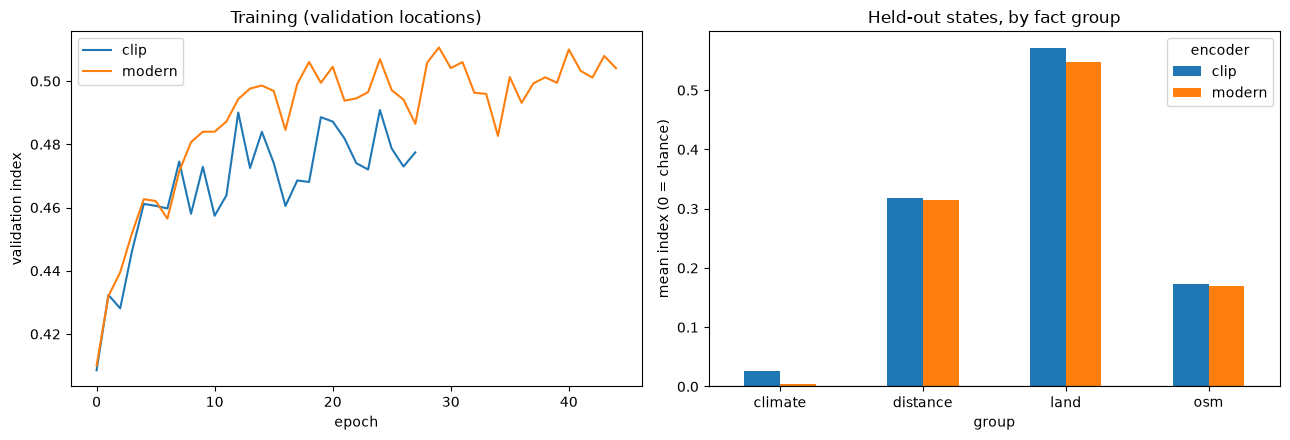

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for enc, h in HIST.items():
    axes[0].plot(h.epoch, h.val_index, label=enc)
axes[0].set(xlabel="epoch", ylabel="validation index", title="Training (validation locations)")
axes[0].legend()
g = CON[CON.heldout].groupby(["encoder", "group"])["index"].mean().unstack(0)
g.plot.bar(ax=axes[1], rot=0)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(ylabel="mean index (0 = chance)", title="Held-out states, by fact group")
fig.tight_layout()
fig.savefig(FIG / "11_aether_us.png", dpi=120)
print(f"Run time {(time.time() - T_START) / 60:.1f} min")

## Best and worst concepts in the held-out states (CLIP encoder)

In [13]:
h = CON[(CON.encoder == "clip") & CON.heldout].dropna(subset=["index"])
pd.concat([h.nlargest(10, "index"), h.nsmallest(10, "index")])[["pool", "group", "text", "index"]].round(3)

,pool,group,text,index
494,minnesota,land,open water,0.911
738,georgia,land,cropland,0.900
497,minnesota,land,cropland,0.894
482,minnesota,land,corn fields,0.894
483,minnesota,land,soybean fields,0.872
728,georgia,land,cotton fields,0.831
515,minnesota,osm,water,0.829
729,georgia,land,other annual crops,0.820
735,georgia,land,open water,0.812
723,georgia,land,corn fields,0.811
